# ЛР3. Анализ результатов

In [1]:
import json
import os
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.contingency_tables import mcnemar

from prepare_e import TARGET, load, to_matrix

SEED = 42
N_BOOT = 1000
MODELS = ["gigachat_max", "alice_flash", "gpt_oss", "qwen_local"]
NAMES = {"gigachat_max": "GigaChat-2-Max", "alice_flash": "Alice AI Flash",
         "gpt_oss": "gpt-oss-120b", "qwen_local": "Qwen3-4B (локально)"}
TYPES = ["A", "B", "C", "D", "F"]
# Официальные тарифы, ₽ за 1000 токенов (вход, выход)
PRICES = {"gigachat_max": (0.65, 0.65),  # пакет GigaChat Max: 1950 ₽ за 3 млн токенов (вход и выход вместе)
          "alice_flash": (0.10, 0.20),   # Yandex AI Studio, Alice AI LLM Flash
          "gpt_oss": (0.30, 0.30),       # Yandex AI Studio, gpt-oss-120b 
          "qwen_local": (0.0, 0.0)}   
QWEN_RAM_GB = 5.1  # `ollama ps`: qwen3:4b с окном 16384 токенов

pd.set_option("display.width", 200)
os.makedirs("results/tables", exist_ok=True)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def boot_ci(values, n=N_BOOT, seed=SEED):
    """95% доверительный интервал среднего: n раз берём задачи с возвращением, 2,5-й и 97,5-й перцентили."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = [values[rng.integers(0, len(values), len(values))].mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])


def fmt_ci(values):
    lo, hi = boot_ci(values)
    return f"{np.mean(values):.0%} [{lo:.0%}; {hi:.0%}]"

## 1. Данные 

In [ ]:
bank = pd.read_csv("data/bank.csv")
ans = pd.read_csv("results/bank_answers.csv")
cd = pd.read_csv("results/cd_scores.csv")  # средние оценки проверяющих 

ans["ok"] = ans["correct"].map({True: 1, False: 0, "True": 1, "False": 0})
cd["ok_C"] = (cd["C"] >= 1.5).astype(float)
cd["ok_D"] = (cd["D_result"] >= 0.5).astype(float)
cd["ok"] = cd["ok_C"].where(cd["id"].str.startswith("C"), cd["ok_D"])
ans = ans.merge(cd[["id", "model", "ok"]], on=["id", "model"], how="left", suffixes=("", "_cd"))
ans["ok"] = ans["ok"].fillna(ans["ok_cd"]).astype(int)

ok = ans.pivot(index="id", columns="model", values="ok").loc[bank["id"], MODELS]  # задачи в порядке банка
types = bank.set_index("id")["type"]
print(ok.rename(columns=NAMES).T.to_string())

id                   A1  A2  A3  A4  A5  A6  B1  B2  B3  B4  B5  B6  C1  C2  C3  C4  C5  D1  D2  D3  D4  D5  F1  F2  F3  F4  F5  F6  F7  F8  F9  F10
model                                                                                                                                               
GigaChat-2-Max        1   0   0   1   0   0   1   1   1   1   1   1   0   1   0   1   1   1   1   1   1   1   1   0   0   1   0   1   1   0   1    1
Alice AI Flash        1   1   1   1   1   0   1   0   1   1   1   0   0   1   1   0   1   1   1   1   1   1   1   0   1   1   0   0   1   0   1    1
gpt-oss-120b          1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   0   0   1   1   1   1   1   1   1   1   1   1    1
Qwen3-4B (локально)   1   1   1   1   1   1   1   0   1   1   1   1   1   0   0   0   1   0   1   0   1   1   1   1   1   1   1   1   1   1   1    1


## 2. Методика: точные ID моделей и даты запросов (из журнала `results/calls.jsonl`)

In [3]:
calls = pd.DataFrame([json.loads(line) for line in open("results/calls.jsonl", encoding="utf-8")])
calls = calls[calls["error"].isna() & calls["model"].isin(MODELS)]
calls = calls[calls["tag"].str.match(r"(bank|pilot|E\d+):")]
calls["time_msk"] = pd.to_datetime(calls["time_utc"]) + pd.Timedelta(hours=3)
meta = calls.groupby("model").agg(id_модели=("server_model", "first"), температура=("temperature", "first"),
                                  первый_запрос_МСК=("time_msk", "min"), последний_запрос_МСК=("time_msk", "max"),
                                  запросов=("tag", "size")).loc[MODELS]
meta["первый_запрос_МСК"] = meta["первый_запрос_МСК"].dt.strftime("%Y-%m-%d %H:%M")
meta["последний_запрос_МСК"] = meta["последний_запрос_МСК"].dt.strftime("%Y-%m-%d %H:%M")
meta.rename(index=NAMES).to_csv("results/tables/models.csv")
meta.rename(index=NAMES)

,id_модели,температура,первый_запрос_МСК,последний_запрос_МСК,запросов
model,,,,,
GigaChat-2-Max,GigaChat-2-Max:2.0.30.01,0.0,2026-11-01 21:42,2026-11-01 22:28,337
Alice AI Flash,gpt://aliceai-llm-flash/latest,0.0,2026-11-01 21:42,2026-11-01 22:04,337
gpt-oss-120b,openai/gpt-oss-120b,0.0,2026-11-01 21:42,2026-11-02 22:58,347
Qwen3-4B (локально),qwen3:4b,0.0,2026-11-01 21:43,2026-11-03 09:45,357


## 3. Точность с 95% доверительными интервалами (бутстреп, 1000 ресэмплов задач)

Интервалы широкие, потому что задач мало: в каждом типе 5–10, одна задача — это 10–20 процентных пунктов.

In [4]:
rows = []
for m in MODELS:
    row = {"модель": NAMES[m], "все 32": fmt_ci(ok[m])}
    for t in TYPES:
        row[t] = fmt_ci(ok.loc[types == t, m])
    rows.append(row)
acc_table = pd.DataFrame(rows).set_index("модель")
acc_table.to_csv("results/tables/accuracy_ci.csv")
acc_table

,все 32,A,B,C,D,F
модель,,,,,,
GigaChat-2-Max,69% [50%; 84%],33% [0%; 67%],100% [100%; 100%],60% [20%; 100%],100% [100%; 100%],60% [30%; 90%]
Alice AI Flash,72% [56%; 88%],83% [50%; 100%],67% [33%; 100%],60% [20%; 100%],100% [100%; 100%],60% [30%; 90%]
gpt-oss-120b,94% [84%; 100%],100% [100%; 100%],100% [100%; 100%],100% [100%; 100%],60% [20%; 100%],100% [100%; 100%]
Qwen3-4B (локально),81% [69%; 94%],100% [100%; 100%],83% [50%; 100%],40% [0%; 80%],60% [20%; 100%],100% [100%; 100%]


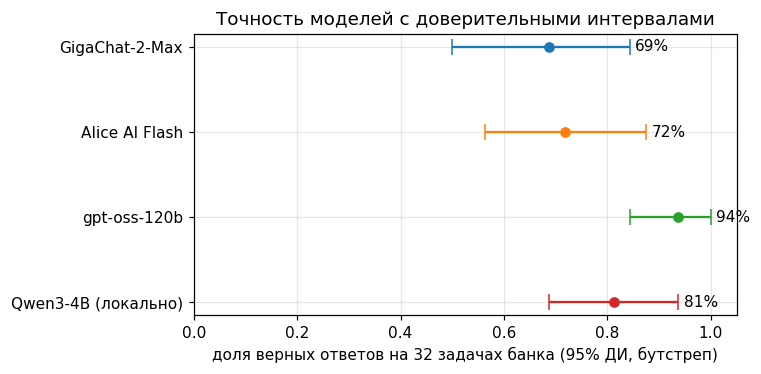

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, m in enumerate(MODELS):
    lo, hi = boot_ci(ok[m])
    mean = ok[m].mean()
    ax.errorbar(mean, i, xerr=[[mean - lo], [hi - mean]], fmt="o", capsize=5, color=f"C{i}")
    ax.text(hi + 0.01, i, f"{mean:.0%}", va="center")
ax.set_yticks(range(len(MODELS)), [NAMES[m] for m in MODELS])
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("доля верных ответов на 32 задачах банка (95% ДИ, бутстреп)")
ax.set_title("Точность моделей с доверительными интервалами")
fig.tight_layout()
fig.savefig("figures/accuracy_ci.png")

## 4. Тепловая карта
Для E (классификация) в ячейке balanced accuracy, точность там не подходит из-за дисбаланса классов

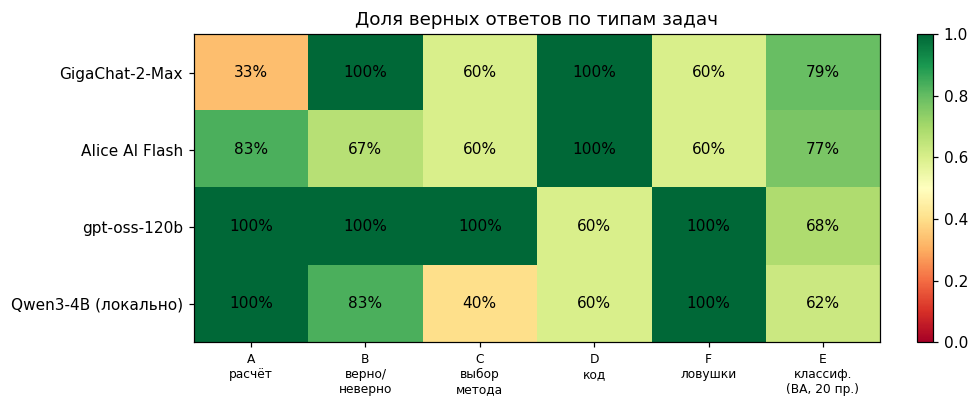

In [6]:
e = pd.read_csv("results/e_answers.csv")
e["pred_eff"] = e["pred"].where(e["pred"].notna(), 1 - e["y_true"])  # нет ответа -> ошибка

heat = ok.groupby(types).mean().T.loc[MODELS]
heat["E"] = [balanced_accuracy_score(g["y_true"], g["pred_eff"])
             for m in MODELS for _, g in [(m, e[(e.model == m) & (e.shots == 20)])]]
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(heat.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1]), ["A\nрасчёт", "B\nверно/\nневерно", "C\nвыбор\nметода", "D\nкод",
                                     "F\nловушки", "E\nклассиф.\n(BA, 20 пр.)"], fontsize=8)
ax.set_yticks(range(len(MODELS)), [NAMES[m] for m in MODELS])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.0%}", ha="center", va="center")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03)
ax.set_title("Доля верных ответов по типам задач")
fig.tight_layout()
fig.savefig("figures/heatmap.png")

## 5. Тест Макнемара для всех пар моделей (32 задачи, `exact=True`)

Тест смотрит только на задачи, где модели разошлись: b — решила только первая, c — только вторая.
p < 0,05 — разница вряд ли случайна.

In [24]:
rows = []
for m1, m2 in combinations(MODELS, 2):
    a, b_ = ok[m1], ok[m2]
    table = [[((a == 1) & (b_ == 1)).sum(), ((a == 1) & (b_ == 0)).sum()],
             [((a == 0) & (b_ == 1)).sum(), ((a == 0) & (b_ == 0)).sum()]]
    rows.append({"пара": f"{NAMES[m1]} — {NAMES[m2]}", "точность 1": f"{a.mean():.0%}", "точность 2": f"{b_.mean():.0%}",
                 "только 1-я верно (b)": table[0][1], "только 2-я верно (c)": table[1][0],
                 "p": round(mcnemar(table, exact=True).pvalue, 4)})
mcn = pd.DataFrame(rows)
mcn["значимо (p<0,05)"] = np.where(mcn["p"] < 0.05, "да", "нет")
mcn.to_csv("results/tables/mcnemar.csv", index=False)
mcn

,пара,точность 1,точность 2,только 1-я верно (b),только 2-я верно (c),p,"значимо (p<0,05)"
0,GigaChat-2-Max — Alice AI Flash,69%,72%,4,5,1.0000,нет
1,GigaChat-2-Max — gpt-oss-120b,69%,94%,2,10,0.0386,да
2,GigaChat-2-Max — Qwen3-4B (локально),69%,81%,5,9,0.4240,нет
3,Alice AI Flash — gpt-oss-120b,72%,94%,2,9,0.0654,нет
4,Alice AI Flash — Qwen3-4B (локально),72%,81%,4,7,0.5488,нет
5,gpt-oss-120b — Qwen3-4B (локально),94%,81%,5,1,0.2188,нет


## 6. Доля отказов («НЕЛЬЗЯ ОПРЕДЕЛИТЬ» или ответ не распознан)

В F7 и F8 данных действительно не хватает, там отказ правильный. В остальных 30 задачах отказ — ошибка.

In [8]:
ans["отказ"] = ans["answer"].isna() | ans["answer"].astype(str).str.contains("НЕЛЬЗЯ", case=False)
need_refusal = ans["id"].isin(["F7", "F8"])
ref = pd.DataFrame({
    "отказов всего (из 32)": ans.groupby("model")["отказ"].sum(),
    "доля отказов": ans.groupby("model")["отказ"].mean().map("{:.0%}".format),
    "оправданные (F7, F8; из 2)": ans[need_refusal].groupby("model")["отказ"].sum(),
    "неоправданные (из 30)": ans[~need_refusal].groupby("model")["отказ"].sum(),
}).loc[MODELS].rename(index=NAMES)
ref.to_csv("results/tables/refusals.csv")
print(ans[ans["отказ"] & ~need_refusal][["model", "id"]].to_string(index=False))
ref

     model id
qwen_local C2
qwen_local C3
qwen_local C4


,отказов всего (из 32),доля отказов,"оправданные (F7, F8; из 2)",неоправданные (из 30)
model,,,,
GigaChat-2-Max,1,3%,1,0
Alice AI Flash,1,3%,1,0
gpt-oss-120b,2,6%,2,0
Qwen3-4B (локально),5,16%,2,3


## 7. Код (тип D): запускаемость, корректность, методологические ошибки

In [9]:
review = pd.read_csv("review/бланк_проверяющий_1_заполнен.csv", sep=";", dtype=str, encoding="utf-8-sig")
key = pd.read_csv("review/ключ.csv")
d = key.merge(review[["код", "запустился (авто)"]], on="код").merge(cd[["код", "D_result", "D_method"]], on="код")
d = d[d["id"].str.startswith("D")]
d["запустился"] = d["запустился (авто)"].astype(int)
dm = d.groupby("model").agg(**{"pass@1 (запустился)": ("запустился", "mean"),
                               "результат в допуске": ("D_result", "mean"),
                               "доля с методологическими ошибками": ("D_method", lambda s: 1 - s.mean())})
dm = dm.loc[MODELS].rename(index=NAMES)
dm.to_csv("results/tables/code_d.csv")
dm.style.format("{:.0%}")

,pass@1 (запустился),результат в допуске,доля с методологическими ошибками
model,,,
GigaChat-2-Max,100%,100%,0%
Alice AI Flash,100%,100%,0%
gpt-oss-120b,80%,60%,0%
Qwen3-4B (локально),60%,60%,40%


## 8. Согласие двух проверяющих (каппа Коэна) и баллы по рубрике 0–2 для B и C

B, кроме автопроверки по вердикту, оценена двумя проверяющими вслепую по рубрике задания:
2 — вердикт и обоснование верны, 1 — вердикт верный, обоснование ошибочное или отсутствует, 0 — вердикт неверный.

In [25]:
r1 = review
r2 = pd.read_csv("review/бланк_проверяющий_2_заполнен.csv", sep=";", dtype=str, encoding="utf-8-sig")
rows = []
for col, name in [("балл C (0-2)", "C: балл 0–2"), ("D: результат в допуске (0/1)", "D: результат"),
                  ("D: методология (1 нет ошибок / 0 есть)", "D: методология")]:
    mask = r1[col].notna() & (r1[col] != "—")
    x, y = r1.loc[mask, col].astype(int), r2.loc[mask, col].astype(int)
    rows.append({"оценка": name, "ответов": int(mask.sum()), "совпало": int((x == y).sum()),
                 "каппа Коэна": round(cohen_kappa_score(x, y), 3)})
b1 = pd.read_csv("review/бланк_B_проверяющий_1_заполнен.csv", sep=";", dtype=str, encoding="utf-8-sig")
b2 = pd.read_csv("review/бланк_B_проверяющий_2_заполнен.csv", sep=";", dtype=str, encoding="utf-8-sig")
x, y = b1["балл B (0-2)"].astype(int), b2["балл B (0-2)"].astype(int)
rows.insert(0, {"оценка": "B: балл 0–2", "ответов": len(x), "совпало": int((x == y).sum()),
                "каппа Коэна": round(cohen_kappa_score(x, y), 3)})
kappa = pd.DataFrame(rows)
kappa.to_csv("results/tables/kappa.csv", index=False)

bs = pd.read_csv("results/b_scores.csv")  # среднее двух проверяющих (tools/kappa.py)
rubric = pd.DataFrame({
    "B: верный вердикт (авто)": ok[types == "B"].mean(),
    "B: средний балл 0–2": bs.groupby("model")["B"].mean(),
    "C: средний балл 0–2": cd[cd["id"].str.startswith("C")].groupby("model")["C"].mean(),
}).loc[MODELS].rename(index=NAMES)
rubric.to_csv("results/tables/rubric_bc.csv")
print(kappa.to_string(index=False))
rubric.round(2)

        оценка  ответов  совпало  каппа Коэна
   B: балл 0–2       24       24        1.000
   C: балл 0–2       20       19        0.907
  D: результат       20       20        1.000
D: методология       20       20        1.000


,B: верный вердикт (авто),B: средний балл 0–2,C: средний балл 0–2
model,,,
GigaChat-2-Max,1.00,2.00,1.5
Alice AI Flash,0.67,1.33,1.6
gpt-oss-120b,1.00,2.00,2.0
Qwen3-4B (локально),0.83,0.83,0.8


## 9. Калибровка уверенности: ECE и диаграмма надёжности

Модели в каждом ответе писали «УВЕРЕННОСТЬ: 0–100». Разбиваем ответы на 5 групп по уверенности и в каждой
сравниваем среднюю уверенность с долей верных. ECE — взвешенное среднее этих разниц (0 — идеальная калибровка).
Почти все уверенности 80–100, поэтому группы берём по этому диапазону.

,средняя уверенность,точность,ECE
model,,,
GigaChat-2-Max,0.98,0.69,0.29
Alice AI Flash,0.97,0.72,0.25
gpt-oss-120b,0.96,0.94,0.10
Qwen3-4B (локально),0.97,0.81,0.17


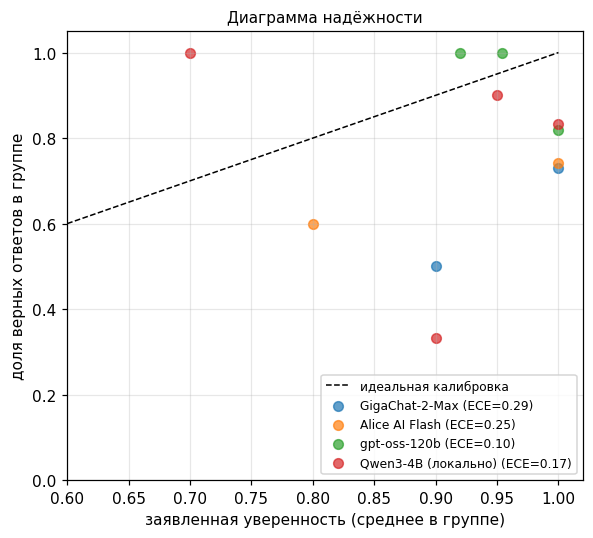

In [11]:
BINS = [0, 80, 90, 95, 100, 101]  # 5 групп: <80, 80–89, 90–94, 95–99, 100
cal = ans[["model", "confidence", "ok"]].dropna()
cal["группа"] = pd.cut(cal["confidence"], BINS, right=False, labels=["<80", "80–89", "90–94", "95–99", "100"])


def ece(g):
    s = g.groupby("группа", observed=True).agg(n=("ok", "size"), conf=("confidence", "mean"), acc=("ok", "mean"))
    return (s["n"] * (s["conf"] / 100 - s["acc"]).abs()).sum() / s["n"].sum()


calib = pd.DataFrame({"средняя уверенность": cal.groupby("model")["confidence"].mean() / 100,
                      "точность": cal.groupby("model")["ok"].mean(),
                      "ECE": [ece(cal[cal.model == m]) for m in sorted(cal.model.unique())]}).loc[MODELS]
calib.rename(index=NAMES).to_csv("results/tables/calibration.csv")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0.6, 1], [0.6, 1], "k--", lw=1, label="идеальная калибровка")
for i, m in enumerate(MODELS):
    s = cal[cal.model == m].groupby("группа", observed=True).agg(conf=("confidence", "mean"), acc=("ok", "mean"),
                                                                n=("ok", "size"))
    ax.scatter(s["conf"] / 100, s["acc"], s=40, color=f"C{i}", alpha=0.7,
               label=f"{NAMES[m]} (ECE={calib.loc[m, 'ECE']:.2f})")
ax.set_xlim(0.6, 1.02)
ax.set_ylim(0, 1.05)
ax.set_xlabel("заявленная уверенность (среднее в группе)")
ax.set_ylabel("доля верных ответов в группе")
ax.set_title("Диаграмма надёжности", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figures/reliability.png")
calib.rename(index=NAMES).style.format("{:.2f}")

## 10. Тип E: LLM как классификатор отказов (AI4I 2020, 100 тестовых строк, из них 20 отказов)

Основные метрики — F1 класса «отказ» и balanced accuracy. Accuracy приводим только чтобы показать,
что константа «отказа нет» уже даёт 80%. Бейзлайны обучены на тех же 5 / 20 строках, что видела LLM.
ДИ — бутстреп по 100 тестовым строкам.

In [12]:
df_e = load()
split = json.load(open("data/e_split.json", encoding="utf-8"))
test = df_e.loc[split["test"]]
X_te, y_te = to_matrix(test), test[TARGET].to_numpy()

preds = {("константа «нет отказа»", 0): DummyClassifier(strategy="most_frequent")
         .fit(to_matrix(df_e), df_e[TARGET]).predict(X_te)}
for k in (5, 20):
    part = df_e.loc[split[f"shots{k}"]]
    for name, clf in [("LogisticRegression", make_pipeline(StandardScaler(), LogisticRegression())),
                      ("GaussianNB", GaussianNB())]:
        preds[(name, k)] = clf.fit(to_matrix(part), part[TARGET]).predict(X_te)
for m in MODELS:
    for k in (0, 5, 20):
        g = e[(e.model == m) & (e.shots == k)].set_index("row_id").loc[split["test"]]
        preds[(NAMES[m], k)] = g["pred_eff"].astype(int).to_numpy()
no_answer = e.groupby(["model", "shots"])["pred"].apply(lambda s: s.isna().sum())


def boot_metric(metric, y, p, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        vals.append(metric(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])


f1 = lambda y, p: f1_score(y, p, zero_division=0)
rows = []
for (name, k), p in preds.items():
    lo, hi = boot_metric(f1, y_te, p)
    lo2, hi2 = boot_metric(balanced_accuracy_score, y_te, p)
    model_key = {v: k_ for k_, v in NAMES.items()}.get(name)
    rows.append({"модель": name, "примеров": k, "F1 «отказ»": f"{f1(y_te, p):.2f} [{lo:.2f}; {hi:.2f}]",
                 "balanced acc.": f"{balanced_accuracy_score(y_te, p):.2f} [{lo2:.2f}; {hi2:.2f}]",
                 "accuracy": f"{(y_te == p).mean():.2f}",
                 "без ответа": int(no_answer.get((model_key, k), 0)) if model_key else 0,
                 "_f1": f1(y_te, p), "_ba": balanced_accuracy_score(y_te, p)})
e_table = pd.DataFrame(rows)
e_table.drop(columns=["_f1", "_ba"]).to_csv("results/tables/e_metrics.csv", index=False)
e_table.drop(columns=["_f1", "_ba"])

,модель,примеров,F1 «отказ»,balanced acc.,accuracy,без ответа
0,константа «нет отказа»,0,0.00 [0.00; 0.00],0.50 [0.50; 0.50],0.80,0
1,LogisticRegression,5,0.40 [0.13; 0.63],0.62 [0.54; 0.73],0.85,0
2,GaussianNB,5,0.00 [0.00; 0.00],0.50 [0.50; 0.50],0.80,0
3,LogisticRegression,20,0.31 [0.08; 0.52],0.59 [0.51; 0.68],0.82,0
4,GaussianNB,20,0.51 [0.33; 0.67],0.71 [0.60; 0.82],0.77,0
5,GigaChat-2-Max,0,0.34 [0.23; 0.44],0.51 [0.50; 0.52],0.21,0
6,GigaChat-2-Max,5,0.61 [0.46; 0.75],0.83 [0.76; 0.89],0.76,0
7,GigaChat-2-Max,20,0.65 [0.47; 0.81],0.79 [0.69; 0.90],0.85,0
8,Alice AI Flash,0,0.34 [0.23; 0.44],0.51 [0.50; 0.52],0.21,0
9,Alice AI Flash,5,0.47 [0.33; 0.60],0.72 [0.64; 0.79],0.58,0


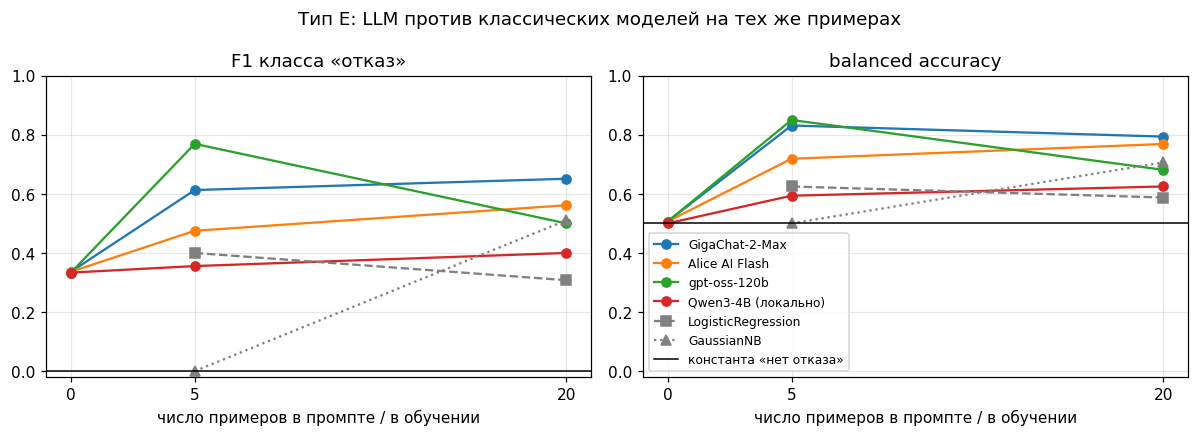

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "_f1", "F1 класса «отказ»"), (axes[1], "_ba", "balanced accuracy")]:
    for i, m in enumerate(MODELS):
        s = e_table[e_table["модель"] == NAMES[m]]
        ax.plot(s["примеров"], s[col], "o-", color=f"C{i}", label=NAMES[m])
    for name, style in [("LogisticRegression", "s--"), ("GaussianNB", "^:")]:
        s = e_table[e_table["модель"] == name]
        ax.plot(s["примеров"], s[col], style, color="gray", label=name)
    const = e_table[e_table["модель"] == "константа «нет отказа»"][col].iloc[0]
    ax.axhline(const, color="black", lw=1, label="константа «нет отказа»")
    ax.set_xticks([0, 5, 20])
    ax.set_xlabel("число примеров в промпте / в обучении")
    ax.set_title(title)
    ax.set_ylim(-0.02, 1)
axes[1].legend(fontsize=8)
fig.suptitle("Тип E: LLM против классических моделей на тех же примерах")
fig.tight_layout()
fig.savefig("figures/e_classification.png")

## 11. Цена и скорость

Стоимость — по официальным тарифам, даже если мы пользовались бесплатным лимитом. Учтены все успешные запросы,
включая обрезанные ответы gpt-oss, которые пришлось повторить (за них тоже пришлось бы платить).
GigaChat не учитывает в счётчике закешированную часть промпта, поэтому для него входные токены
пересчитаны методом `tokens_count` (`tools/gigachat_tokens.py`): берём большее из отчёта и пересчёта.

In [14]:
gtok = pd.read_csv("results/gigachat_prompt_tokens.csv").set_index("tag")["prompt_tokens"]
calls["part"] = np.where(calls["tag"].str.startswith("bank:"), "банк",
                         np.where(calls["tag"].str.startswith("E"), "E", "пилот"))
is_giga = calls["model"] == "gigachat_max"
calls.loc[is_giga, "tokens_in"] = np.maximum(calls.loc[is_giga, "tokens_in"],
                                             calls.loc[is_giga, "tag"].map(gtok).fillna(0))
calls["cost"] = [(ti * PRICES[m][0] + to * PRICES[m][1]) / 1000
                 for m, ti, to in zip(calls["model"], calls["tokens_in"], calls["tokens_out"])]

bank_calls = calls[calls["part"] == "банк"]
e_calls = calls[calls["part"] == "E"]
cost = pd.DataFrame({
    "верных из 32": ok.sum(),
    "токенов на задачу (вход+выход)": bank_calls.groupby("model").apply(lambda g: (g.tokens_in + g.tokens_out).mean()),
    "средняя задержка, с": ans.groupby("model")["seconds"].mean(),
    "стоимость банка, ₽": bank_calls.groupby("model")["cost"].sum(),
    "стоимость типа E (300 запросов), ₽": e_calls.groupby("model")["cost"].sum(),
}).loc[MODELS]
cost["₽ за 1 правильный ответ (банк)"] = cost["стоимость банка, ₽"] / cost["верных из 32"]
cost = cost.round({"токенов на задачу (вход+выход)": 0, "средняя задержка, с": 1, "стоимость банка, ₽": 3,
                   "стоимость типа E (300 запросов), ₽": 2, "₽ за 1 правильный ответ (банк)": 4})
cost.rename(index=NAMES).to_csv("results/tables/cost.csv")
q = ans[ans.model == "qwen_local"]["seconds"]
qe = e[e.model == "qwen_local"]
print(f"Qwen3-4B локально, банк: {q.mean() / 60:.1f} мин на задачу в среднем "
      f"(от {q.min():.0f} с до {q.max() / 60:.0f} мин), весь банк {q.sum() / 3600:.1f} ч, память {QWEN_RAM_GB} ГБ ОЗУ")
print(f"Qwen3-4B локально, тип E: {qe['seconds'].mean():.0f} с на запрос в среднем, по режимам "
      f"{qe.groupby('shots')['seconds'].mean().round(0).to_dict()}, все 300 запросов {qe['seconds'].sum() / 3600:.1f} ч")
cost.rename(index=NAMES)

Qwen3-4B локально, банк: 6.4 мин на задачу в среднем (от 46 с до 25 мин), весь банк 3.4 ч, память 5.1 ГБ ОЗУ
Qwen3-4B локально, тип E: 65 с на запрос в среднем, по режимам {0: 56.0, 5: 51.0, 20: 89.0}, все 300 запросов 5.4 ч


C:\Users\Anastasia\AppData\Local\Temp\ipykernel_4160\251113079.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "токенов на задачу (вход+выход)": bank_calls.groupby("model").apply(lambda g: (g.tokens_in + g.tokens_out).mean()),


,верных из 32,токенов на задачу (вход+выход),"средняя задержка, с","стоимость банка, ₽","стоимость типа E (300 запросов), ₽",₽ за 1 правильный ответ (банк)
model,,,,,,
GigaChat-2-Max,22,438.0,4.8,9.112,147.44,0.4142
Alice AI Flash,23,467.0,3.9,2.227,22.78,0.0968
gpt-oss-120b,30,829.0,3.5,7.958,191.38,0.2652
Qwen3-4B (локально),26,2781.0,383.0,0.000,0.00,0.0000


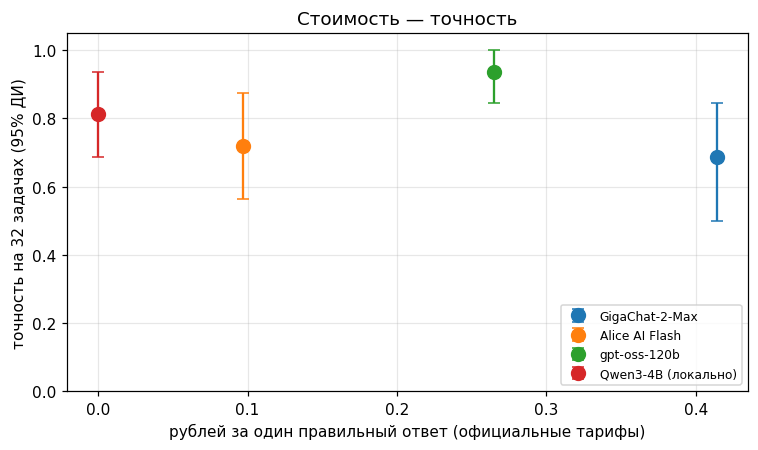

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, m in enumerate(MODELS):
    x, y = cost.loc[m, "₽ за 1 правильный ответ (банк)"], ok[m].mean()
    lo, hi = boot_ci(ok[m])
    ax.errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt="o", ms=9, capsize=4, color=f"C{i}", label=NAMES[m])
ax.set_xlabel("рублей за один правильный ответ (официальные тарифы)")
ax.set_ylabel("точность на 32 задачах (95% ДИ)")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Стоимость — точность")
fig.tight_layout()
fig.savefig("figures/cost_accuracy.png")

## 12. Гипотеза H1 (группа 1): изменённые числа

**Утверждение:** на учебниковых задачах A1–A6 точность выше, чем на тех же задачах с изменёнными числами F1–F6.
**Проверка:** 6 пар × 4 модели = 24 пары ответов; тест Макнемара по парам (только пары, где A и F разошлись).
**Критерий:** гипотеза подтверждается, если «только A верно» встречается значимо чаще, чем «только F верно» (p < 0,05).

In [16]:
pairs = bank.dropna(subset=["pair"])
a_ids = pairs[pairs.type == "A"].sort_values("pair")["id"].tolist()
f_ids = pairs[pairs.type == "F"].sort_values("pair")["id"].tolist()
A, F = ok.loc[a_ids].to_numpy(), ok.loc[f_ids].to_numpy()  # 6 пар × 4 модели
h1 = pd.DataFrame({"точность A1–A6": A.mean(0), "точность F1–F6": F.mean(0),
                   "только A верно": ((A == 1) & (F == 0)).sum(0), "только F верно": ((A == 0) & (F == 1)).sum(0)},
                  index=[NAMES[m] for m in MODELS])
both = [[((A == 1) & (F == 1)).sum(), ((A == 1) & (F == 0)).sum()],
        [((A == 0) & (F == 1)).sum(), ((A == 0) & (F == 0)).sum()]]
h1_p = mcnemar(both, exact=True).pvalue
h1.loc["Все 4 модели (24 пары)"] = [A.mean(), F.mean(), both[0][1], both[1][0]]
h1.to_csv("results/tables/h1.csv")
print(f"Все 24 пары: обе верно {both[0][0]}, только A {both[0][1]}, только F {both[1][0]}, обе неверно {both[1][1]}; "
      f"Макнемар exact p = {h1_p:.3f}")
print(pd.DataFrame(A, index=a_ids, columns=MODELS).astype(int).join(
    pd.DataFrame(F, index=a_ids, columns=[c + "_F" for c in MODELS]).astype(int)).to_string())
h1.style.format({"точность A1–A6": "{:.0%}", "точность F1–F6": "{:.0%}",
                 "только A верно": "{:.0f}", "только F верно": "{:.0f}"})

Все 24 пары: обе верно 17, только A 2, только F 1, обе неверно 4; Макнемар exact p = 1.000
    gigachat_max  alice_flash  gpt_oss  qwen_local  gigachat_max_F  alice_flash_F  gpt_oss_F  qwen_local_F
A1             1            1        1           1               1              1          1             1
A2             0            1        1           1               0              0          1             1
A3             0            1        1           1               0              1          1             1
A4             1            1        1           1               1              1          1             1
A5             0            1        1           1               0              0          1             1
A6             0            0        1           1               1              0          1             1


,точность A1–A6,точность F1–F6,только A верно,только F верно
GigaChat-2-Max,33%,50%,0,1
Alice AI Flash,83%,50%,2,0
gpt-oss-120b,100%,100%,0,0
Qwen3-4B (локально),100%,100%,0,0
Все 4 модели (24 пары),79%,75%,2,1


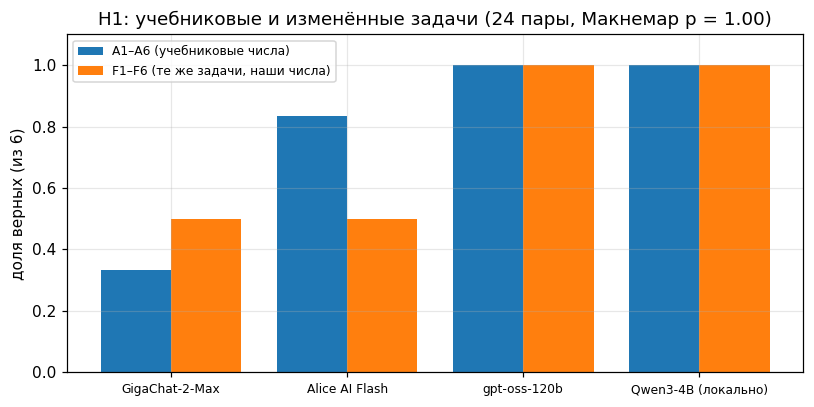

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(MODELS))
ax.bar(x - 0.2, A.mean(0), 0.4, label="A1–A6 (учебниковые числа)")
ax.bar(x + 0.2, F.mean(0), 0.4, label="F1–F6 (те же задачи, наши числа)")
ax.set_xticks(x, [NAMES[m] for m in MODELS], fontsize=8)
ax.set_ylim(0, 1.1)
ax.set_ylabel("доля верных (из 6)")
ax.set_title(f"H1: учебниковые и изменённые задачи (24 пары, Макнемар p = {h1_p:.2f})")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/h1.png")

## 13. Гипотеза H5 (группа 2): размер модели

**Утверждение:** маленькая модель (Qwen3-4B) отстаёт от больших сильнее в расчётах (A), чем в теории (B).
**Отставание** = средняя точность GigaChat-2-Max и gpt-oss-120b минус точность Qwen3-4B, отдельно на A и на B.
**Критерий:** отставание на A больше, чем на B, и 95% ДИ разницы (бутстреп по задачам внутри A и B) не содержит 0.

In [18]:
def lag(sub):
    return sub[["gigachat_max", "gpt_oss"]].mean(axis=1).mean() - sub["qwen_local"].mean()


okA, okB = ok[types == "A"], ok[types == "B"]
lag_A, lag_B = lag(okA), lag(okB)
rng = np.random.default_rng(SEED)
diffs = [lag(okA.iloc[rng.integers(0, len(okA), len(okA))]) - lag(okB.iloc[rng.integers(0, len(okB), len(okB))])
         for _ in range(N_BOOT)]
h5_lo, h5_hi = np.percentile(diffs, [2.5, 97.5])
h5 = pd.DataFrame({"большие (среднее)": [okA[["gigachat_max", "gpt_oss"]].values.mean(),
                                         okB[["gigachat_max", "gpt_oss"]].values.mean()],
                   "Qwen3-4B": [okA["qwen_local"].mean(), okB["qwen_local"].mean()],
                   "отставание Qwen": [lag_A, lag_B]}, index=["A (расчёт)", "B (теория)"])
h5.to_csv("results/tables/h5.csv")
print(f"Отставание на A минус отставание на B = {lag_A - lag_B:+.0%}, 95% ДИ [{h5_lo:+.0%}; {h5_hi:+.0%}]")
h5.style.format("{:+.0%}")

Отставание на A минус отставание на B = -50%, 95% ДИ [-92%; -17%]


,большие (среднее),Qwen3-4B,отставание Qwen
A (расчёт),+67%,+100%,-33%
B (теория),+100%,+83%,+17%


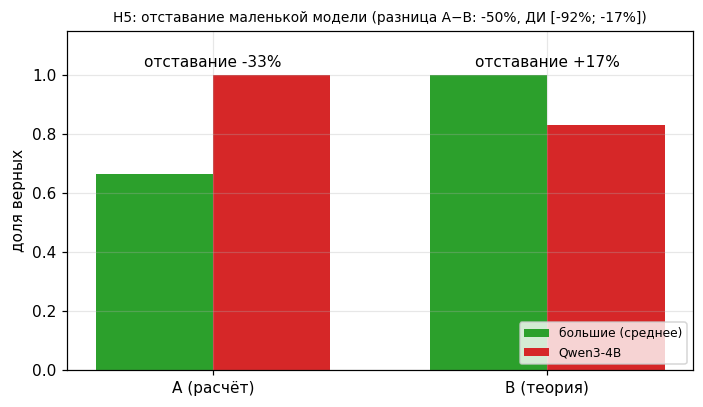

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(2)
for i, (col, color) in enumerate([("большие (среднее)", "C2"), ("Qwen3-4B", "C3")]):
    ax.bar(x + (i - 0.5) * 0.35, h5[col], 0.35, label=col, color=color)
for j, v in enumerate(h5["отставание Qwen"]):
    ax.text(j, 1.03, f"отставание {v:+.0%}", ha="center")
ax.set_xticks(x, h5.index)
ax.set_ylim(0, 1.15)
ax.set_ylabel("доля верных")
ax.set_title(f"H5: отставание маленькой модели (разница A−B: {lag_A - lag_B:+.0%}, ДИ [{h5_lo:+.0%}; {h5_hi:+.0%}])",
             fontsize=9)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figures/h5.png")

## 14. Гипотеза H12 (группа 4): LLM как классификатор на малой выборке

**Утверждение:** при 5 примерах few-shot LLM не хуже логистической регрессии, а при 20 — уже проигрывает.
**Проверка:** разница F1 «отказ» (LLM − LogReg) на тех же 100 тестовых строках, 95% ДИ бутстрепом по строкам
(парный: на каждом шаге одни и те же строки для LLM и LogReg). То же для balanced accuracy.
**Критерий (по F1 «отказ», основная метрика):** «не хуже» при 5 — LLM не проигрывает значимо (верхняя граница
ДИ разницы > 0); «проигрывает» при 20 — верхняя граница ДИ разницы < 0. Гипотеза подтверждается для модели,
если выполнены обе части.

In [20]:
def boot_diff(metric, y, p1, p2, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        vals.append(metric(y[idx], p1[idx]) - metric(y[idx], p2[idx]))
    return np.percentile(vals, [2.5, 97.5])


rows = []
for m in MODELS:
    for k in (5, 20):
        p_llm, p_lr = preds[(NAMES[m], k)], preds[("LogisticRegression", k)]
        for mname, metric in [("F1 «отказ»", f1), ("balanced acc.", balanced_accuracy_score)]:
            dlt = metric(y_te, p_llm) - metric(y_te, p_lr)
            lo, hi = boot_diff(metric, y_te, p_llm, p_lr)
            rows.append({"модель": NAMES[m], "примеров": k, "метрика": mname, "LLM": round(metric(y_te, p_llm), 2),
                         "LogReg": round(metric(y_te, p_lr), 2), "LLM − LogReg": round(dlt, 2),
                         "95% ДИ разницы": f"[{lo:+.2f}; {hi:+.2f}]",
                         "вывод": "LLM лучше" if lo > 0 else ("LLM хуже" if hi < 0 else "разница незначима")})
h12 = pd.DataFrame(rows)
h12.to_csv("results/tables/h12.csv", index=False)

h12_facts, part1, part2 = [], [], []
for m in MODELS:
    s = h12[(h12["модель"] == NAMES[m]) & (h12["метрика"] == "F1 «отказ»")].set_index("примеров")
    hi5 = float(s.loc[5, "95% ДИ разницы"].strip("[]").split(";")[1])
    hi20 = float(s.loc[20, "95% ДИ разницы"].strip("[]").split(";")[1])
    part1.append(hi5 > 0)   # при 5 примерах LLM не хуже LogReg
    part2.append(hi20 < 0)  # при 20 примерах LLM значимо хуже LogReg
    h12_facts.append(f"{NAMES[m]}: Δ5 {s.loc[5, 'LLM − LogReg']:+.2f}, Δ20 {s.loc[20, 'LLM − LogReg']:+.2f}")
h12_verdict = (f"часть «при 5 не хуже» выполнена у {sum(part1)} из 4 моделей; "
               f"«при 20 проигрывает» — у {sum(part2)} из 4; целиком подтвердилась у "
               f"{sum(a and b for a, b in zip(part1, part2))} из 4")
print(h12_verdict)
h12

часть «при 5 не хуже» выполнена у 4 из 4 моделей; «при 20 проигрывает» — у 0 из 4; целиком подтвердилась у 0 из 4


,модель,примеров,метрика,LLM,LogReg,LLM − LogReg,95% ДИ разницы,вывод
0,GigaChat-2-Max,5,F1 «отказ»,0.61,0.40,0.21,[-0.08; +0.49],разница незначима
1,GigaChat-2-Max,5,balanced acc.,0.83,0.62,0.21,[+0.09; +0.32],LLM лучше
2,GigaChat-2-Max,20,F1 «отказ»,0.65,0.31,0.34,[+0.11; +0.59],LLM лучше
3,GigaChat-2-Max,20,balanced acc.,0.79,0.59,0.21,[+0.09; +0.32],LLM лучше
4,Alice AI Flash,5,F1 «отказ»,0.47,0.40,0.07,[-0.20; +0.35],разница незначима
5,Alice AI Flash,5,balanced acc.,0.72,0.62,0.09,[-0.02; +0.21],разница незначима
6,Alice AI Flash,20,F1 «отказ»,0.56,0.31,0.25,[-0.00; +0.50],разница незначима
7,Alice AI Flash,20,balanced acc.,0.77,0.59,0.18,[+0.06; +0.30],LLM лучше
8,gpt-oss-120b,5,F1 «отказ»,0.77,0.40,0.37,[+0.10; +0.63],LLM лучше
9,gpt-oss-120b,5,balanced acc.,0.85,0.62,0.22,[+0.10; +0.34],LLM лучше


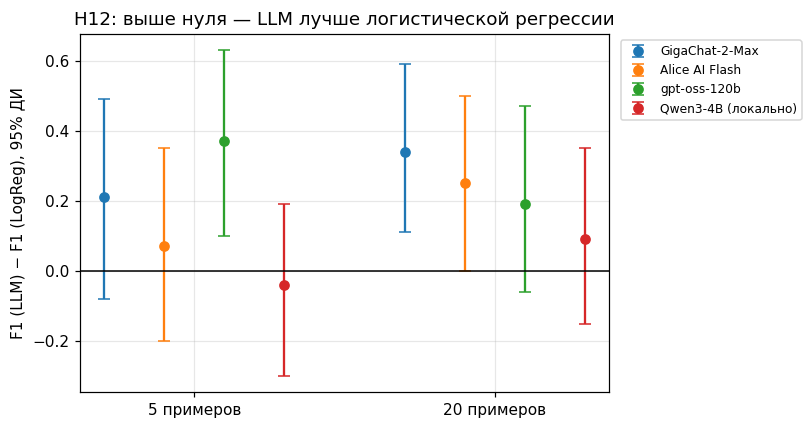

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 4))
sub = h12[h12["метрика"] == "F1 «отказ»"]
for j, k in enumerate((5, 20)):
    s = sub[sub["примеров"] == k]
    for i, (_, r) in enumerate(s.iterrows()):
        lo, hi = [float(v) for v in r["95% ДИ разницы"].strip("[]").split(";")]
        xpos = j * 5 + i
        ax.errorbar(xpos, r["LLM − LogReg"], yerr=[[r["LLM − LogReg"] - lo], [hi - r["LLM − LogReg"]]],
                    fmt="o", capsize=4, color=f"C{i}", label=r["модель"] if j == 0 else None)
ax.axhline(0, color="black", lw=1)
ax.set_xticks([1.5, 6.5], ["5 примеров", "20 примеров"])
ax.set_ylabel("F1 (LLM) − F1 (LogReg), 95% ДИ")
ax.set_title("H12: выше нуля — LLM лучше логистической регрессии")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig("figures/h12.png")